# NLP — clasificación multiclase del género (`main_genre_top10`)

Obligatorio MLSI 2026 S2, tarea 7. El objetivo es predecir el género principal de una película (10 géneros más `others`) a partir de sus atributos de texto (título, sinopsis y palabras clave), usando las técnicas de NLP del curso. Esta tarea no forma parte de la competencia de Kaggle, así que todo se evalúa con validación cruzada sobre el train.

1. Carga de datos y desbalance de clases
2. Procesamiento del texto: normalización, tokenización, stopwords, stemming y lematización
3. Representación: TF-IDF
4. Validación y métricas
5. Comparación de preprocesamientos (stemming contra lematización)
6. Comparación de representaciones
7. Comparación de clasificadores
8. Atributos a elección (no textuales)
9. Modelo final: métricas por clase, matriz de confusión y análisis
10. Conclusiones
11. Referencias

## 1. Carga de datos

In [1]:
import os
import re
import time
import urllib.request
import warnings

# El código común (carga de datos, limpieza y folds) está en obl_utils.py.
# En Colab no está el archivo, así que se descarga del repo.
if not os.path.exists('obl_utils.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/obl_utils.py', 'obl_utils.py')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from obl_utils import *

# NLTK: tokenizador, stopwords, stemmers, lematizador (WordNet) y etiquetador gramatical.
# Si no está instalado: pip install nltk
import nltk
for recurso in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger_eng']:
    nltk.download(recurso, quiet=True)
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             make_scorer, precision_score)
from sklearn.model_selection import cross_val_predict, cross_validate
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings('ignore', category=FutureWarning)

GENERO = 'main_genre_top10'

# Carpeta de salida de esta notebook (no hay submission: la tarea no va a Kaggle)
CARPETA_RESULTADOS = 'resultados/NLP_Genero'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

train, _ = cargar_datos()
y = train[GENERO]
print('train:', train.shape)
train[['original_title', 'overview', 'keywords', GENERO]].head()

train: (3602, 14)


,original_title,overview,keywords,main_genre_top10
0,I Spy,"When the Switchblade, the most sophisticated p...",budapest kidnapping boxer secret agent liberat...,Action
1,Split Second,"In a futuristic London, the rising sea levels ...",flooding futuristic police detective,Thriller
2,Gossip,"On a beautiful college campus, something ugly ...",college suspense gossip rumor social experiment,Drama
3,Vicky Cristina Barcelona,Two girlfriends on a summer holiday in Spain b...,barcelona spain menage a trois author,Drama
4,Harry Potter and the Half-Blood Prince,"As Harry begins his sixth year at Hogwarts, he...",witch magic broom school of witchcraft wizardry,Adventure


### 1.1 Atributos de texto y desbalance de clases

Los atributos de texto disponibles son `original_title` (título), `overview` (sinopsis, en inglés) y `keywords` (palabras clave separadas por espacios). La sinopsis es el texto más informativo; las palabras clave son pocas pero muy específicas (por ejemplo, *"serial killer"*, *"vampire"*, *"based on comic"*).

Faltantes: {'original_title': 0, 'overview': 2, 'keywords': 304}


,count,mean,std,min,25%,50%,75%,max
palabras overview,3602.0,52.2,28.1,0.0,30.0,48.0,67.0,175.0
palabras keywords,3602.0,5.8,2.9,0.0,5.0,6.0,8.0,16.0


,películas,proporción
main_genre_top10,,
Drama,894,0.248
Comedy,783,0.217
Action,581,0.161
others,318,0.088
Adventure,255,0.071
Horror,222,0.062
Crime,151,0.042
Thriller,140,0.039
Animation,94,0.026


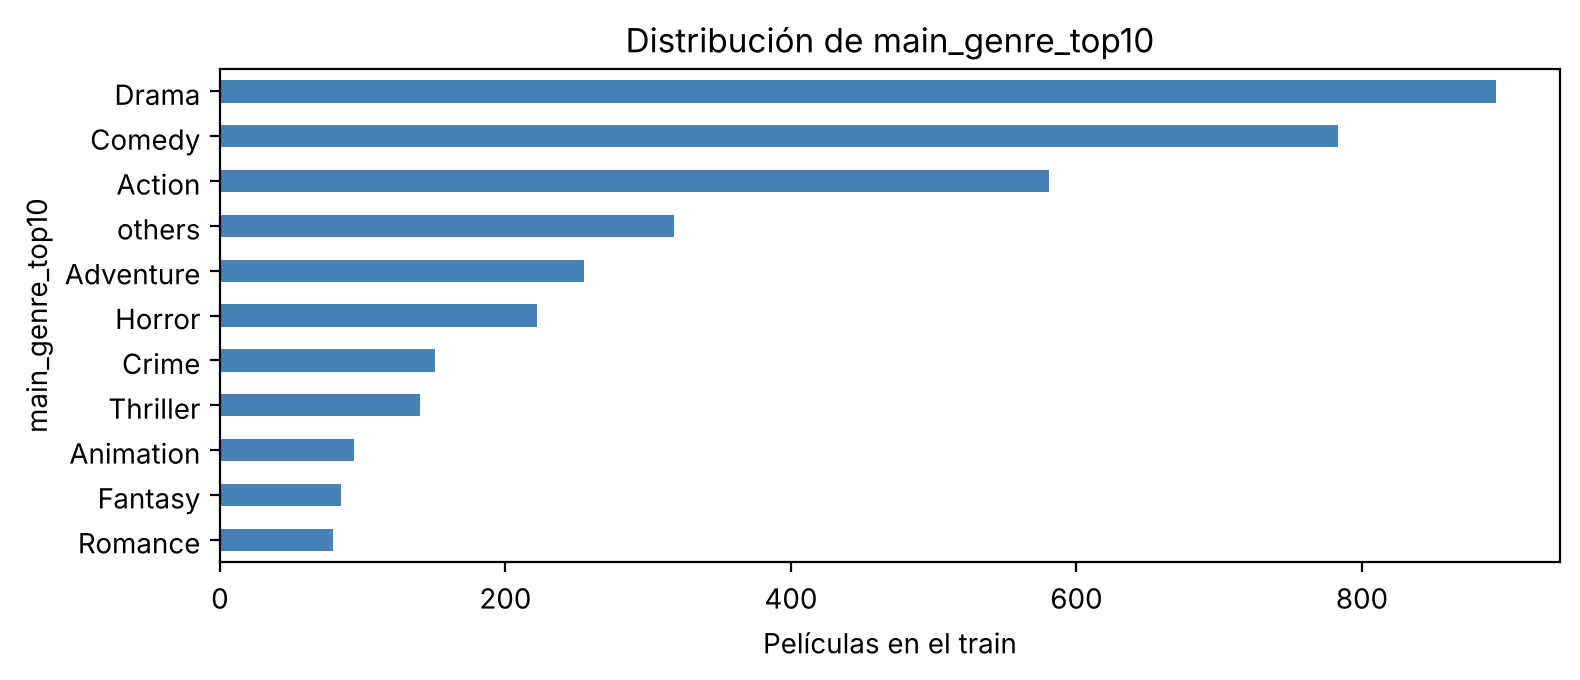

In [2]:
largo = pd.DataFrame({
    'palabras overview': train['overview'].fillna('').str.split().str.len(),
    'palabras keywords': train['keywords'].fillna('').str.split().str.len(),
})
print('Faltantes:', train[['original_title', 'overview', 'keywords']].isna().sum().to_dict())
display(largo.describe().round(1).T)

distribucion = pd.DataFrame({
    'películas': y.value_counts(),
    'proporción': y.value_counts(normalize=True).round(3),
})
display(distribucion)

fig, ax = plt.subplots(figsize=(8, 3.5))
distribucion['películas'].sort_values().plot.barh(ax=ax, color='steelblue')
ax.set_xlabel('Películas en el train')
ax.set_title('Distribución de main_genre_top10')
plt.tight_layout()
plt.show()

**Lectura.** Las clases están muy desbalanceadas: Drama (24,8%) y Comedy (21,7%) suman casi la mitad del train, mientras que Animation, Fantasy y Romance tienen menos de 100 películas cada una (2,2% a 2,6%), unas 11 veces menos que Drama. Un modelo que siempre predice Drama ya obtiene 24,8% de accuracy, así que el accuracy por sí solo no sirve para evaluar (sección 4). Además, `others` no es un género sino un grupo de géneros fuera del top 10, con contenido heterogéneo.

## 2. Procesamiento del texto

### 2.1 Texto de entrada

Para cada película se arma un único texto concatenando **título + sinopsis + palabras clave**. El título aporta poco por sí solo pero a veces es muy informativo (*"Scary Movie"*, *"Toy Story"*); los faltantes (2 sinopsis y 304 películas sin keywords) se reemplazan por texto vacío, así que esas películas se clasifican con lo que tengan. En la sección 6 se compara contra usar solo la sinopsis o vectorizar los campos por separado.

### 2.2 Pasos del preprocesamiento

1. **Normalización:** todo a minúsculas, así *"Love"* y *"love"* son el mismo término.
2. **Tokenización:** `nltk.word_tokenize` separa el texto en palabras y signos de puntuación (maneja contracciones y puntuación mejor que separar por espacios). Se conservan solo los tokens formados por letras: se descartan números, puntuación y fragmentos como *"'s"* o *"n't"*, que no aportan al género.
3. **Eliminación de stopwords:** se eliminan las 198 palabras funcionales del inglés de NLTK (*the, of, and, his...*) y los tokens de una letra. Son las palabras más frecuentes y aparecen en todos los géneros por igual, así que solo agregan ruido y dimensiones.
4. **Reducción a la raíz** (dos alternativas que se comparan en la sección 5):
   - **Stemming:** recorta sufijos con reglas fijas. Se prueban el stemmer de Porter (Porter, 1980) y el Snowball (Porter2), su versión revisada. Es rápido pero produce raíces que no son palabras (*"family"* → *"famili"*) y a veces une palabras de distinto significado (*"universe"* y *"university"* → *"univers"*).
   - **Lematización:** lleva cada palabra a su forma de diccionario (lema) usando WordNet (*"stolen"* → *"steal"*, *"children"* → *"child"*). Necesita saber la categoría gramatical: sin ella, WordNet trata todo como sustantivo y no transforma los verbos (*"killed"* queda igual). Por eso primero se etiqueta cada token con `nltk.pos_tag` (el etiquetado se hace **antes** de quitar stopwords, porque necesita el contexto de la oración). También se prueba la lematización sin etiquetado, para medir cuánto aporta.

La idea de los dos últimos pasos es que *murder, murdered, murders, murderer* cuenten como un mismo término: con unas 3.600 películas, cada palabra aparece pocas veces, y agrupar sus variantes da más ejemplos por término y un vocabulario más chico.

**Sin data leakage:** estos pasos se aplican película por película y no aprenden nada de los datos (las stopwords y las reglas son fijas), así que se pueden aplicar una sola vez antes de la validación cruzada. Lo que sí aprende de los datos (el vocabulario y los pesos IDF del TF-IDF) se ajusta dentro de cada fold (sección 3).

In [3]:
STOPWORDS = set(stopwords.words('english'))
porter = PorterStemmer()
snowball = SnowballStemmer('english')
lematizador = WordNetLemmatizer()

def categoria_wordnet(etiqueta):
    # Traduce la etiqueta de nltk.pos_tag (Penn Treebank) a la categoría de WordNet
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(etiqueta[0], wordnet.NOUN)

def tokenizar(texto):
    # Normalización + tokenización: minúsculas y solo tokens formados por letras
    return [t for t in nltk.word_tokenize(texto.lower()) if re.fullmatch(r'[a-z]+', t)]

def sin_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS and len(t) > 1]

def preprocesar(texto, variante):
    tokens = tokenizar(texto)
    if variante == 'tokenizacion':
        return ' '.join(tokens)
    if variante == 'lematizacion':
        # el etiquetado gramatical va antes de quitar stopwords porque usa el contexto
        tokens = [lematizador.lemmatize(t, categoria_wordnet(et)) for t, et in nltk.pos_tag(tokens)]
    tokens = sin_stopwords(tokens)
    if variante == 'stemming_porter':
        tokens = [porter.stem(t) for t in tokens]
    elif variante == 'stemming_snowball':
        tokens = [snowball.stem(t) for t in tokens]
    elif variante == 'lematizacion_sin_pos':
        tokens = [lematizador.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

VARIANTES = ['tokenizacion', 'stopwords', 'stemming_porter', 'stemming_snowball',
             'lematizacion_sin_pos', 'lematizacion']

# Ejemplo con una sinopsis
ejemplo = train['overview'][0]
print('Original:\n ', ejemplo[:230], '...\n')
for v in VARIANTES:
    print(f'{v}:\n ', preprocesar(ejemplo, v)[:200], '...\n')

Original:
  When the Switchblade, the most sophisticated prototype stealth fighter created yet, is stolen from the U.S. government, one of the United States' top spies, Alex Scott, is called to action. What he doesn't expect is to get teamed  ...

tokenizacion:
  when the switchblade the most sophisticated prototype stealth fighter created yet is stolen from the government one of the united states top spies alex scott is called to action what he does expect is ...

stopwords:
  switchblade sophisticated prototype stealth fighter created yet stolen government one united states top spies alex scott called action expect get teamed cocky civilian world class boxing champion kell ...

stemming_porter:
  switchblad sophist prototyp stealth fighter creat yet stolen govern one unit state top spi alex scott call action expect get team cocki civilian world class box champion kelli robinson danger top secr ...

stemming_snowball:
  switchblad sophist prototyp stealth fighter creat yet stolen gove

lematizacion_sin_pos:
  switchblade sophisticated prototype stealth fighter created yet stolen government one united state top spy alex scott called action expect get teamed cocky civilian world class boxing champion kelly r ...

lematizacion:
  switchblade sophisticated prototype stealth fighter create yet steal government one united state top spy alex scott call action expect get team cocky civilian world class box champion kelly robinson d ...



In [4]:
# Texto de entrada: título + sinopsis + keywords
texto = (train['original_title'].fillna('') + '. ' + train['overview'].fillna('') + '. '
         + train['keywords'].fillna(''))

# Se preprocesa una vez cada variante (no aprende de los datos, ver 2.2)
X = limpiar(train).drop(columns=[GENERO])     # variables no textuales, usadas en la sección 8
inicio = time.time()
for v in VARIANTES:
    X[f'texto_{v}'] = texto.map(lambda s: preprocesar(s, v))
# Variantes de la sección 6: solo sinopsis, y sinopsis y keywords por separado
sinopsis = train['original_title'].fillna('') + '. ' + train['overview'].fillna('')
X['sinopsis_lematizacion'] = sinopsis.map(lambda s: preprocesar(s, 'lematizacion'))
X['keywords_lematizacion'] = train['keywords'].fillna('').map(lambda s: preprocesar(s, 'lematizacion'))
print(f'Preprocesamiento: {time.time() - inicio:.0f} s')

# Tamaño del vocabulario y largo promedio de cada variante
vocabulario = pd.DataFrame([{
    'variante': v,
    'términos distintos': len(set(' '.join(X[f'texto_{v}']).split())),
    'términos con frecuencia >= 2': int((pd.Series(' '.join(X[f'texto_{v}']).split()).value_counts() >= 2).sum()),
    'tokens por película': round(X[f'texto_{v}'].str.split().str.len().mean(), 1),
} for v in VARIANTES])
vocabulario

Preprocesamiento: 31 s


,variante,términos distintos,términos con frecuencia >= 2,tokens por película
0,tokenizacion,19403,10863,59.4
1,stopwords,19251,10720,36.2
2,stemming_porter,13938,8246,36.2
3,stemming_snowball,13831,8196,36.2
4,lematizacion_sin_pos,17262,9756,36.2
5,lematizacion,16060,9053,36.2


**Lectura.** Quitar stopwords reduce el largo de cada texto de 59 a 36 tokens (casi 40% de los tokens son palabras funcionales) pero casi no reduce el vocabulario, porque son pocas palabras muy repetidas. La reducción a la raíz es la que achica el vocabulario: el stemming lo baja de 19.251 a unos 13.900 términos (−28%) y la lematización a 16.060 (−17%), porque es más conservadora (solo une formas de una misma palabra del diccionario). La lematización con etiquetado gramatical reduce más que sin él (16.060 contra 17.262), porque también lleva los verbos a su infinitivo (*created* → *create*, *stolen* → *steal*); sin etiquetado esos verbos quedan iguales, como se ve en el ejemplo. Porter y Snowball dan resultados casi idénticos.

## 3. Representación: TF-IDF

Cada texto se representa como un vector de **TF-IDF** (*term frequency - inverse document frequency*; Salton y Buckley, 1988; Manning et al., 2008, cap. 6) con `TfidfVectorizer`:

$$\text{tfidf}(t, d) = \text{tf}(t, d) \cdot \left(\log\frac{1 + n}{1 + \text{df}(t)} + 1\right)$$

donde $\text{tf}(t, d)$ es la cantidad de veces que aparece el término $t$ en la película $d$, $n$ la cantidad de películas y $\text{df}(t)$ la cantidad de películas que contienen $t$. Cada vector se normaliza a largo 1 (norma L2).

- **Por qué TF-IDF y no solo conteos (bolsa de palabras):** el IDF baja el peso de los términos que aparecen en muchas películas de todos los géneros (*life, find, new, man*) y sube el de los términos raros y específicos (*zombie, heist, spaceship*), que son los que distinguen géneros. La normalización L2 hace comparables sinopsis largas y cortas. En la sección 6 se compara contra la bolsa de palabras.
- **`sublinear_tf=True`:** usa $1 + \log(\text{tf})$ en lugar de $\text{tf}$, así una palabra repetida 5 veces no pesa 5 veces más que una que aparece una vez.
- **`min_df=2`:** se descartan los términos que aparecen en una sola película (nombres propios, errores de tipeo), que no sirven para generalizar y son la mayoría del vocabulario.
- **Unigramas** por defecto; en la sección 6 se prueban también bigramas (pares de palabras consecutivas, como *"serial killer"* o *"high school"*).

El vectorizador va dentro de un `Pipeline` junto al clasificador, así el vocabulario y los IDF se calculan **solo con el train de cada fold**.

## 4. Validación y métricas

**Validación: k-fold cross-validation estratificado** con `crear_cv()` de `obl_utils.py`: 5 folds, `shuffle=True` y `SEED = 42`, los mismos que en el resto del obligatorio. Estratificado por `main_genre_top10`, así cada fold mantiene la proporción de cada género; esto es importante acá porque los géneros chicos tienen menos de 100 películas (unas 16 a 19 por fold de validación) y una división al azar podría dejar un fold casi sin ejemplos de alguno.

**Métricas:** accuracy, y precision, recall y F1 con **promedio macro** (el promedio simple de la métrica de cada género, sin ponderar por su tamaño), con su desvío entre folds; también el F1 macro en train para detectar sobreajuste. La métrica principal para elegir es el **F1 macro**: con clases desbalanceadas, el accuracy premia acertar los géneros grandes, y un modelo que nunca predice Romance o Fantasy puede tener buen accuracy; el F1 macro le da el mismo peso a cada género. Las métricas por clase y la matriz de confusión se calculan en la sección 9 con las predicciones de validación de cada fold (`cross_val_predict`).

**Modelos de referencia:** un clasificador que siempre predice la clase mayoritaria (Drama) y uno que predice al azar respetando las proporciones de cada clase. Cualquier modelo útil tiene que superarlos claramente.

In [5]:
METRICAS_GENERO = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, average='macro', zero_division=0),
    'recall': 'recall_macro',
    'f1': 'f1_macro',
}

def crear_pipeline_texto(clasificador, columna='texto_lematizacion', vectorizador=None, extra=None):
    # Vectorizador (TF-IDF por defecto) + clasificador. `extra` agrega transformadores
    # de otras columnas (sección 8). Todo se ajusta dentro de cada fold.
    if vectorizador is None:
        vectorizador = TfidfVectorizer(sublinear_tf=True, min_df=2)
    columnas = [('texto', vectorizador, columna)] + (extra or [])
    return Pipeline([
        ('prep', ColumnTransformer(columnas, remainder='drop')),
        ('modelo', clasificador),
    ])

def evaluar_texto(pipe, X, y, **info):
    # Una fila de resultados: promedio y desvío entre folds de cada métrica + F1 macro en train
    cv = cross_validate(pipe, X, y, cv=crear_cv(), scoring=METRICAS_GENERO,
                        return_train_score=True, n_jobs=-1)
    fila = dict(info)
    for nombre in METRICAS_GENERO:
        fila[nombre] = float(cv[f'test_{nombre}'].mean())
        fila[f'{nombre}_std'] = float(cv[f'test_{nombre}'].std())
    fila['f1_train'] = float(cv['train_f1'].mean())
    return fila

COLUMNAS_TABLA = ['accuracy', 'precision', 'recall', 'f1', 'f1_std', 'f1_train']

referencias = pd.DataFrame([
    evaluar_texto(crear_pipeline_texto(DummyClassifier(strategy='most_frequent')), X, y,
                  modelo='Siempre Drama'),
    evaluar_texto(crear_pipeline_texto(DummyClassifier(strategy='stratified', random_state=SEED)), X, y,
                  modelo='Azar estratificado'),
])
referencias[['modelo'] + COLUMNAS_TABLA].round(3)

,modelo,accuracy,precision,recall,f1,f1_std,f1_train
0,Siempre Drama,0.248,0.023,0.091,0.036,0.000,0.036
1,Azar estratificado,0.154,0.092,0.092,0.092,0.006,0.093


## 5. Comparación de preprocesamientos: stemming contra lematización

Se comparan las seis variantes de la sección 2 con la misma representación (TF-IDF de unigramas) y dos clasificadores distintos, para que la conclusión no dependa de uno solo: una **regresión logística** multinomial con `class_weight='balanced'` y `C=2`, y **Complement Naive Bayes** con `alpha=0.3` (los hiperparámetros se ajustan en la sección 7; acá se fijan en valores razonables para aislar el efecto del preprocesamiento).

In [6]:
CLASIFICADORES_PREP = {
    'Regresión logística': lambda: LogisticRegression(C=2, class_weight='balanced', max_iter=3000),
    'Complement NB': lambda: ComplementNB(alpha=0.3),
}
filas = []
for v in VARIANTES:
    for nombre, crear in CLASIFICADORES_PREP.items():
        filas.append(evaluar_texto(crear_pipeline_texto(crear(), columna=f'texto_{v}'), X, y,
                                   variante=v, clasificador=nombre))
tabla_prep = pd.DataFrame(filas)
tabla_prep.to_csv(f'{CARPETA_RESULTADOS}/nlp_preprocesamiento.csv', index=False)
tabla_prep[['variante', 'clasificador'] + COLUMNAS_TABLA].round(3)

,variante,clasificador,accuracy,precision,recall,f1,f1_std,f1_train
0,tokenizacion,Regresión logística,0.428,0.304,0.304,0.300,0.010,0.939
1,tokenizacion,Complement NB,0.449,0.312,0.281,0.279,0.006,0.946
2,stopwords,Regresión logística,0.433,0.307,0.309,0.305,0.009,0.944
3,stopwords,Complement NB,0.444,0.315,0.285,0.284,0.006,0.949
4,stemming_porter,Regresión logística,0.425,0.308,0.315,0.308,0.006,0.924
5,stemming_porter,Complement NB,0.443,0.301,0.283,0.279,0.016,0.918
6,stemming_snowball,Regresión logística,0.429,0.311,0.317,0.311,0.008,0.923
7,stemming_snowball,Complement NB,0.442,0.299,0.282,0.277,0.018,0.917
8,lematizacion_sin_pos,Regresión logística,0.431,0.309,0.311,0.306,0.007,0.936
9,lematizacion_sin_pos,Complement NB,0.446,0.307,0.284,0.281,0.007,0.936


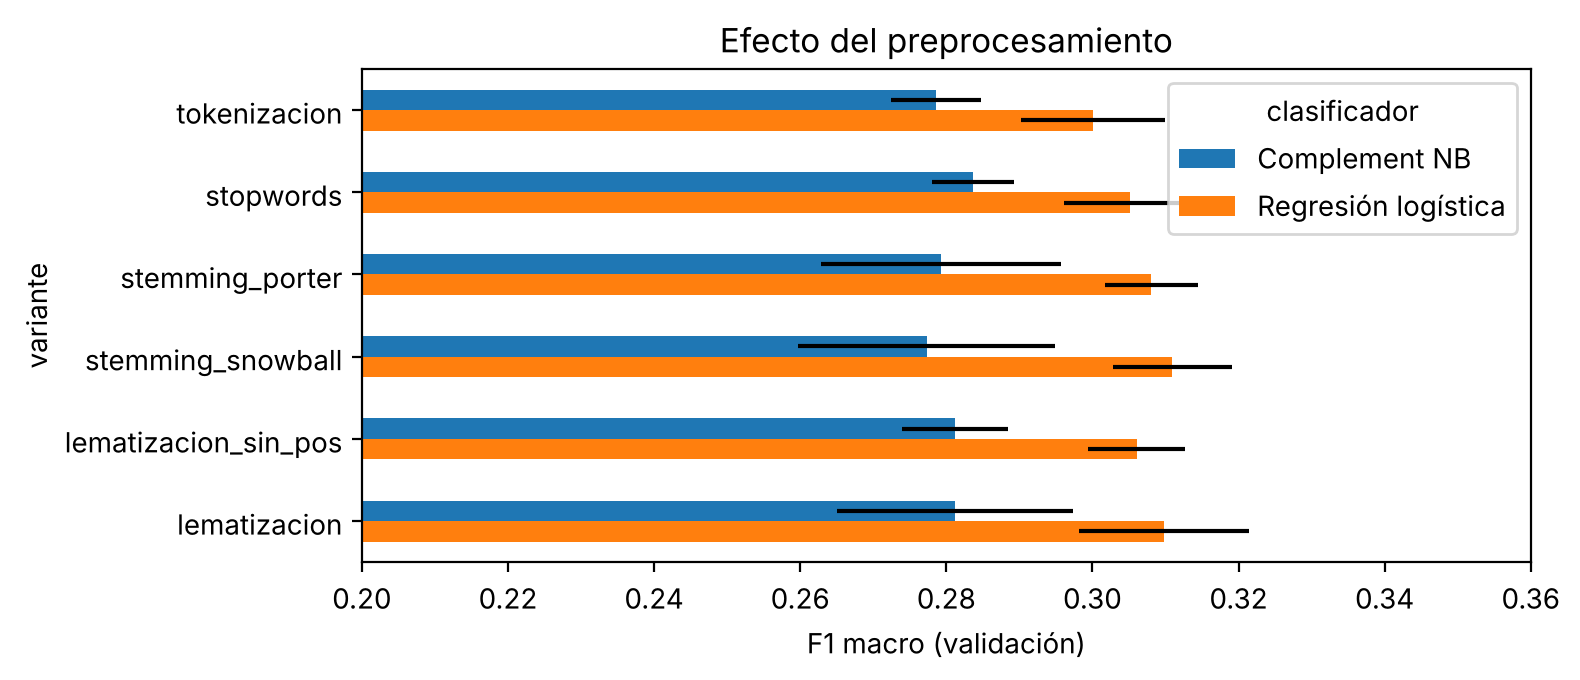

In [7]:
# F1 macro por variante y clasificador
pivote = tabla_prep.pivot(index='variante', columns='clasificador', values='f1').loc[VARIANTES]
fig, ax = plt.subplots(figsize=(8, 3.5))
pivote.plot.barh(ax=ax, xerr=tabla_prep.pivot(index='variante', columns='clasificador', values='f1_std').loc[VARIANTES])
ax.set_xlabel('F1 macro (validación)')
ax.set_xlim(0.2, 0.36)
ax.set_title('Efecto del preprocesamiento')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Lectura.** Las diferencias entre preprocesamientos son chicas y quedan dentro del desvío entre folds (~0,01). Con la regresión logística, quitar stopwords mejora apenas el F1 macro (0,300 → 0,305) y la reducción a la raíz agrega otro poco: stemming Snowball 0,311, lematización 0,310, Porter 0,308 y lematización sin etiquetado 0,306. Con Complement NB todas las variantes quedan entre 0,277 y 0,284, sin un orden claro.

**Stemming contra lematización:** rinden igual. El stemming reduce más el vocabulario, pero eso no se traduce en mejor clasificación, porque TF-IDF con `min_df=2` ya descarta la mayoría de los términos raros. Se elige la **lematización con etiquetado gramatical** porque, con el mismo desempeño, produce términos que son palabras reales (*steal*, *family*) y eso hace interpretables los términos más influyentes de cada género (sección 9.2), mientras que el stemming produce raíces como *famili* o *sophist*. El costo es que es más lenta (el etiquetado gramatical), lo que no importa con 3.600 películas.

Que el preprocesamiento importe poco es esperable: el género se reconoce por palabras de contenido (*murder*, *zombie*, *love*) que sobreviven a cualquiera de las variantes, y la variante más simple ya tiene la mayor parte de la información.

## 6. Comparación de representaciones

Con la variante elegida y la regresión logística de la sección 5 se comparan:

- **Bolsa de palabras** (`CountVectorizer`, conteos sin IDF) contra **TF-IDF**.
- **`min_df`** de 1, 2 y 5.
- **Unigramas** contra **unigramas + bigramas** (`ngram_range=(1, 2)`).
- **Qué texto usar:** solo título + sinopsis, título + sinopsis + keywords en un único texto, o sinopsis y keywords vectorizadas por separado (dos TF-IDF concatenados).

In [8]:
LR_PREP = lambda: LogisticRegression(C=2, class_weight='balanced', max_iter=3000)
tfidf = lambda **kw: TfidfVectorizer(sublinear_tf=True, **{'min_df': 2, **kw})
REPRESENTACIONES = {
    'Bolsa de palabras (conteos), min_df=2': crear_pipeline_texto(LR_PREP(), vectorizador=CountVectorizer(min_df=2)),
    'TF-IDF, min_df=1': crear_pipeline_texto(LR_PREP(), vectorizador=tfidf(min_df=1)),
    'TF-IDF, min_df=2': crear_pipeline_texto(LR_PREP(), vectorizador=tfidf()),
    'TF-IDF, min_df=5': crear_pipeline_texto(LR_PREP(), vectorizador=tfidf(min_df=5)),
    'TF-IDF, min_df=2, uni + bigramas': crear_pipeline_texto(LR_PREP(), vectorizador=tfidf(ngram_range=(1, 2))),
    'TF-IDF solo título + sinopsis': crear_pipeline_texto(LR_PREP(), columna='sinopsis_lematizacion'),
    'TF-IDF sinopsis y keywords por separado': crear_pipeline_texto(
        LR_PREP(), columna='sinopsis_lematizacion',
        extra=[('keywords', tfidf(), 'keywords_lematizacion')]),
}
tabla_repr = pd.DataFrame([evaluar_texto(pipe, X, y, representacion=nombre)
                           for nombre, pipe in REPRESENTACIONES.items()])
tabla_repr.to_csv(f'{CARPETA_RESULTADOS}/nlp_representacion.csv', index=False)
tabla_repr[['representacion'] + COLUMNAS_TABLA].round(3)

,representacion,accuracy,precision,recall,f1,f1_std,f1_train
0,"Bolsa de palabras (conteos), min_df=2",0.390,0.273,0.259,0.262,0.012,1.000
1,"TF-IDF, min_df=1",0.437,0.312,0.315,0.309,0.010,0.947
2,"TF-IDF, min_df=2",0.430,0.309,0.317,0.310,0.012,0.927
3,"TF-IDF, min_df=5",0.408,0.295,0.310,0.300,0.013,0.885
4,"TF-IDF, min_df=2, uni + bigramas",0.441,0.316,0.316,0.311,0.011,0.950
5,TF-IDF solo título + sinopsis,0.399,0.285,0.289,0.283,0.015,0.934
6,TF-IDF sinopsis y keywords por separado,0.401,0.287,0.283,0.283,0.017,0.966


**Lectura.**

- **TF-IDF supera claramente a la bolsa de palabras** (F1 macro 0,310 contra 0,262, casi 5 desvíos), y la bolsa de palabras sobreajusta por completo (F1 en train 1,00). Con conteos sin normalizar, las sinopsis largas tienen vectores más grandes y las palabras comunes dominan; el IDF y la normalización L2 corrigen las dos cosas.
- **`min_df`:** 1 y 2 dan lo mismo (0,309 y 0,310); 5 empeora un poco (0,300), porque descarta términos poco frecuentes pero muy específicos de un género. Se mantiene `min_df=2`, que tiene casi la mitad de las columnas y menos sobreajuste.
- **Bigramas:** no mejoran (0,311 contra 0,310). Con 3.600 películas la gran mayoría de los bigramas aparece muy pocas veces, y los más útiles (*serial killer*, *high school*) ya están representados por sus palabras sueltas.
- **Qué texto usar:** las palabras clave aportan: sin ellas el F1 baja a 0,283. Vectorizarlas por separado también da 0,283: cada bloque se normaliza por separado, así que las pocas palabras clave terminan pesando lo mismo que toda la sinopsis y el modelo sobreajusta más (F1 en train 0,966). Un único texto concatenado es lo mejor.

Se mantiene **TF-IDF de unigramas, `min_df=2`, sobre título + sinopsis + keywords lematizados**.

## 7. Comparación de clasificadores

Con el texto lematizado y TF-IDF de unigramas (`min_df=2`) se comparan cuatro clasificadores lineales, los habituales para texto representado con TF-IDF (miles de columnas y pocas películas), cada uno con una grilla de su hiperparámetro de regularización:

| Clasificador | Idea | Hiperparámetros probados |
|---|---|---|
| Multinomial Naive Bayes | Probabilidad de cada palabra dado el género, suponiendo palabras independientes | `alpha` (suavizado de Laplace): 0,01, 0,1, 0,3, 1 |
| Complement Naive Bayes | Variante de NB que estima los parámetros con las clases *complementarias*; propuesta para clases desbalanceadas (Rennie et al., 2003) | `alpha`: 0,01, 0,1, 0,3, 1 |
| Regresión logística (multinomial) | Modelo lineal con softmax sobre los 11 géneros, regularización L2 | `C`: 0,5, 1, 2, 5, 10 × `class_weight`: ninguno / `balanced` |
| SVM lineal (`LinearSVC`) | Máximo margen, uno contra el resto | `C`: 0,05, 0,1, 0,3, 1 × `class_weight`: ninguno / `balanced` |

`class_weight='balanced'` pondera cada película de forma inversamente proporcional al tamaño de su género, así equivocarse en un Romance pesa unas 11 veces más que en un Drama. Es la forma de atacar el desbalance sin descartar ni duplicar datos. Naive Bayes no admite pesos por clase de la misma forma; Complement NB es su alternativa para el desbalance.

No se usan árboles ni boosting: con miles de columnas dispersas (cada palabra es una columna y casi todas valen 0), los modelos lineales son el estándar para clasificación de texto y rinden igual o mejor con mucho menos costo.

In [9]:
GRILLA = []
for a in [0.01, 0.1, 0.3, 1]:
    GRILLA.append(('Multinomial NB', f'alpha={a}', MultinomialNB(alpha=a)))
    GRILLA.append(('Complement NB', f'alpha={a}', ComplementNB(alpha=a)))
for peso in [None, 'balanced']:
    for C in [0.5, 1, 2, 5, 10]:
        GRILLA.append(('Regresión logística', f'C={C}, class_weight={peso}',
                       LogisticRegression(C=C, class_weight=peso, max_iter=3000)))
    for C in [0.05, 0.1, 0.3, 1]:
        GRILLA.append(('SVM lineal', f'C={C}, class_weight={peso}',
                       LinearSVC(C=C, class_weight=peso)))

inicio = time.time()
tabla_clf = pd.DataFrame([evaluar_texto(crear_pipeline_texto(clf), X, y, clasificador=nombre, hiperparametros=hp)
                          for nombre, hp, clf in GRILLA])
print(f'{len(GRILLA)} combinaciones en {time.time() - inicio:.0f} s')
tabla_clf.to_csv(f'{CARPETA_RESULTADOS}/nlp_clasificadores.csv', index=False)

# Mejor combinación de cada clasificador (por F1 macro)
mejores_clf = (tabla_clf.sort_values('f1', ascending=False).groupby('clasificador', sort=False).head(1)
               .reset_index(drop=True))
mejores_clf[['clasificador', 'hiperparametros'] + COLUMNAS_TABLA].round(3)

26 combinaciones en 18 s


,clasificador,hiperparametros,accuracy,precision,recall,f1,f1_std,f1_train
0,SVM lineal,"C=0.05, class_weight=balanced",0.427,0.307,0.336,0.312,0.017,0.851
1,Regresión logística,"C=2, class_weight=balanced",0.430,0.309,0.317,0.310,0.012,0.927
2,Complement NB,alpha=0.3,0.444,0.316,0.284,0.281,0.016,0.926
3,Multinomial NB,alpha=0.01,0.419,0.331,0.239,0.245,0.010,0.987


In [10]:
# Grilla completa, ordenada por F1 macro
tabla_clf.sort_values('f1', ascending=False)[['clasificador', 'hiperparametros'] + COLUMNAS_TABLA].round(3)

,clasificador,hiperparametros,accuracy,precision,recall,f1,f1_std,f1_train
22,SVM lineal,"C=0.05, class_weight=balanced",0.427,0.307,0.336,0.312,0.017,0.851
23,SVM lineal,"C=0.1, class_weight=balanced",0.424,0.304,0.334,0.311,0.015,0.895
19,Regresión logística,"C=2, class_weight=balanced",0.430,0.309,0.317,0.310,0.012,0.927
18,Regresión logística,"C=1, class_weight=balanced",0.414,0.301,0.321,0.307,0.012,0.866
17,Regresión logística,"C=0.5, class_weight=balanced",0.400,0.300,0.332,0.306,0.015,0.799
20,Regresión logística,"C=5, class_weight=balanced",0.435,0.311,0.304,0.303,0.011,0.980
21,Regresión logística,"C=10, class_weight=balanced",0.431,0.314,0.295,0.297,0.014,0.996
24,SVM lineal,"C=0.3, class_weight=balanced",0.416,0.286,0.305,0.292,0.017,0.970
25,SVM lineal,"C=1, class_weight=balanced",0.406,0.284,0.286,0.282,0.015,0.999
5,Complement NB,alpha=0.3,0.444,0.316,0.284,0.281,0.016,0.926


**Lectura.**

- **El factor más importante es `class_weight='balanced'`**, más que el clasificador: sin pesos, la mejor regresión logística da F1 macro 0,254 y la mejor SVM 0,269; con pesos, 0,310 y 0,312. Sin pesos los modelos casi no predicen los géneros chicos, lo que se analiza en la sección 9.3.
- **Regresión logística y SVM lineal con pesos empatan** (0,310 ± 0,012 y 0,312 ± 0,017), y en ambas el mejor valor es una regularización intermedia (`C=2` en la logística, `C=0,05` en la SVM, que escala distinto); con menos regularización el F1 en train sube a 0,98–1,00 y el de validación baja.
- **Naive Bayes queda por debajo:** Complement NB llega a 0,281 y Multinomial NB a 0,245. Multinomial NB es el más afectado por el desbalance, porque la probabilidad a priori de cada género empuja las predicciones hacia Drama y Comedy (con `alpha=1` casi solo predice esas dos clases, F1 0,137). Complement NB corrige parte de ese sesgo, como proponen Rennie et al. (2003), pero no lo suficiente.

Se elige la **regresión logística con `C=2` y `class_weight='balanced'`**: empata con la SVM, pero da probabilidades para cada género y un vector de coeficientes por género (sección 9.2), y es la que se usa para agregar atributos en la sección 8.

## 8. Atributos a elección (no textuales)

La letra permite agregar otros atributos. Algunos géneros tienen rasgos que no están en el texto: las películas animadas son más cortas, las de terror tienen presupuestos más bajos, las de aventura y acción más altos y más votos. Se agregan al mejor modelo de texto las variables numéricas ya limpias en `obl_utils.limpiar` (duración, presupuesto, recaudación, votos, popularidad y año, con imputación por mediana y estandarización dentro de cada fold) y, por separado, el idioma original y el director (one-hot, agrupando las categorías con pocas películas). Como al agregar columnas cambia la escala del problema, se vuelve a probar el valor de `C`.

No se usa `opinion`: no es un atributo de la película sino otra variable a predecir, y no está disponible en el test.

In [11]:
COLS_NUM_GENERO = ['runtime', 'log_budget', 'log_revenue', 'log_vote_count', 'log_popularity', 'anio']
numericas = ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                              ('escalar', StandardScaler())]), COLS_NUM_GENERO)
idioma = ('idioma', OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist'), ['original_language'])
director = ('director', OneHotEncoder(min_frequency=3, handle_unknown='infrequent_if_exist'), ['director'])

COMBINACIONES = {
    'solo texto': [],
    'texto + numéricas': [numericas],
    'texto + numéricas + idioma': [numericas, idioma],
    'texto + numéricas + director': [numericas, director],
}
filas = []
for nombre, extra in COMBINACIONES.items():
    for C in [1, 2, 5]:
        clf = LogisticRegression(C=C, class_weight='balanced', max_iter=3000)
        filas.append(evaluar_texto(crear_pipeline_texto(clf, extra=extra), X, y, atributos=nombre, C=C))
tabla_atrib = pd.DataFrame(filas)
tabla_atrib.to_csv(f'{CARPETA_RESULTADOS}/nlp_atributos.csv', index=False)
tabla_atrib[['atributos', 'C'] + COLUMNAS_TABLA].round(3)

,atributos,C,accuracy,precision,recall,f1,f1_std,f1_train
0,solo texto,1,0.414,0.301,0.321,0.307,0.012,0.866
1,solo texto,2,0.430,0.309,0.317,0.310,0.012,0.927
2,solo texto,5,0.435,0.311,0.304,0.303,0.011,0.980
3,texto + numéricas,1,0.412,0.316,0.357,0.323,0.031,0.763
4,texto + numéricas,2,0.446,0.334,0.356,0.336,0.034,0.877
5,texto + numéricas,5,0.458,0.340,0.346,0.336,0.034,0.969
6,texto + numéricas + idioma,1,0.411,0.314,0.357,0.321,0.034,0.758
7,texto + numéricas + idioma,2,0.443,0.328,0.354,0.333,0.037,0.874
8,texto + numéricas + idioma,5,0.456,0.337,0.344,0.334,0.036,0.969
9,texto + numéricas + director,1,0.411,0.313,0.357,0.320,0.033,0.793


**Lectura.** Agregar las variables numéricas mejora el F1 macro de 0,310 a **0,336** con `C=2` (+0,026, unos 2 desvíos del modelo de solo texto) y el accuracy de 0,430 a 0,446. El idioma y el director no agregan nada sobre eso (0,333 y 0,338): el director aparece en muy pocas películas cada uno (con `min_frequency=3` casi todos quedan agrupados) y el idioma es inglés en el 92% de los casos. El desvío entre folds sube de 0,012 a 0,034 porque las numéricas ayudan mucho más en algunos folds que en otros, así que la mejora debe tomarse con cautela.

Se elige **texto + numéricas, `C=2`**: el director empata pero agrega cientos de columnas a cambio de nada.

## 9. Modelo final

Regresión logística multinomial con `C=2` y `class_weight='balanced'`, sobre TF-IDF de unigramas (`min_df=2`, `sublinear_tf`) del texto título + sinopsis + keywords lematizado con WordNet y etiquetado gramatical, más 6 variables numéricas estandarizadas. Las métricas por clase se calculan con las predicciones de validación de cada fold.

In [12]:
MODELO_FINAL = LogisticRegression(C=2, class_weight='balanced', max_iter=3000)
EXTRA_FINAL = [numericas]
pipe_final = crear_pipeline_texto(MODELO_FINAL, extra=EXTRA_FINAL)

# Predicciones de validación: cada película la predice el modelo del fold que no la vio
y_pred = cross_val_predict(pipe_final, X, y, cv=crear_cv(), n_jobs=-1)
CLASES = y.value_counts().index.tolist()          # de mayor a menor

reporte = pd.DataFrame(classification_report(y, y_pred, labels=CLASES, output_dict=True, zero_division=0)).T
reporte = reporte.rename(columns={'f1-score': 'f1', 'support': 'películas'})
reporte['películas'] = reporte['películas'].astype(int)
reporte.loc['accuracy', ['precision', 'recall']] = np.nan   # en esa fila solo tiene sentido f1 (= accuracy)
reporte.loc['accuracy', 'películas'] = len(y)
reporte.to_csv(f'{CARPETA_RESULTADOS}/nlp_por_clase.csv')
reporte.round(3)

,precision,recall,f1,películas
Drama,0.583,0.525,0.552,894
Comedy,0.567,0.557,0.562,783
Action,0.491,0.444,0.467,581
others,0.283,0.264,0.273,318
Adventure,0.323,0.408,0.360,255
Horror,0.425,0.572,0.488,222
Crime,0.284,0.278,0.281,151
Thriller,0.126,0.143,0.134,140
Animation,0.314,0.585,0.409,94
Fantasy,0.141,0.106,0.121,85


### 9.1 Matriz de confusión

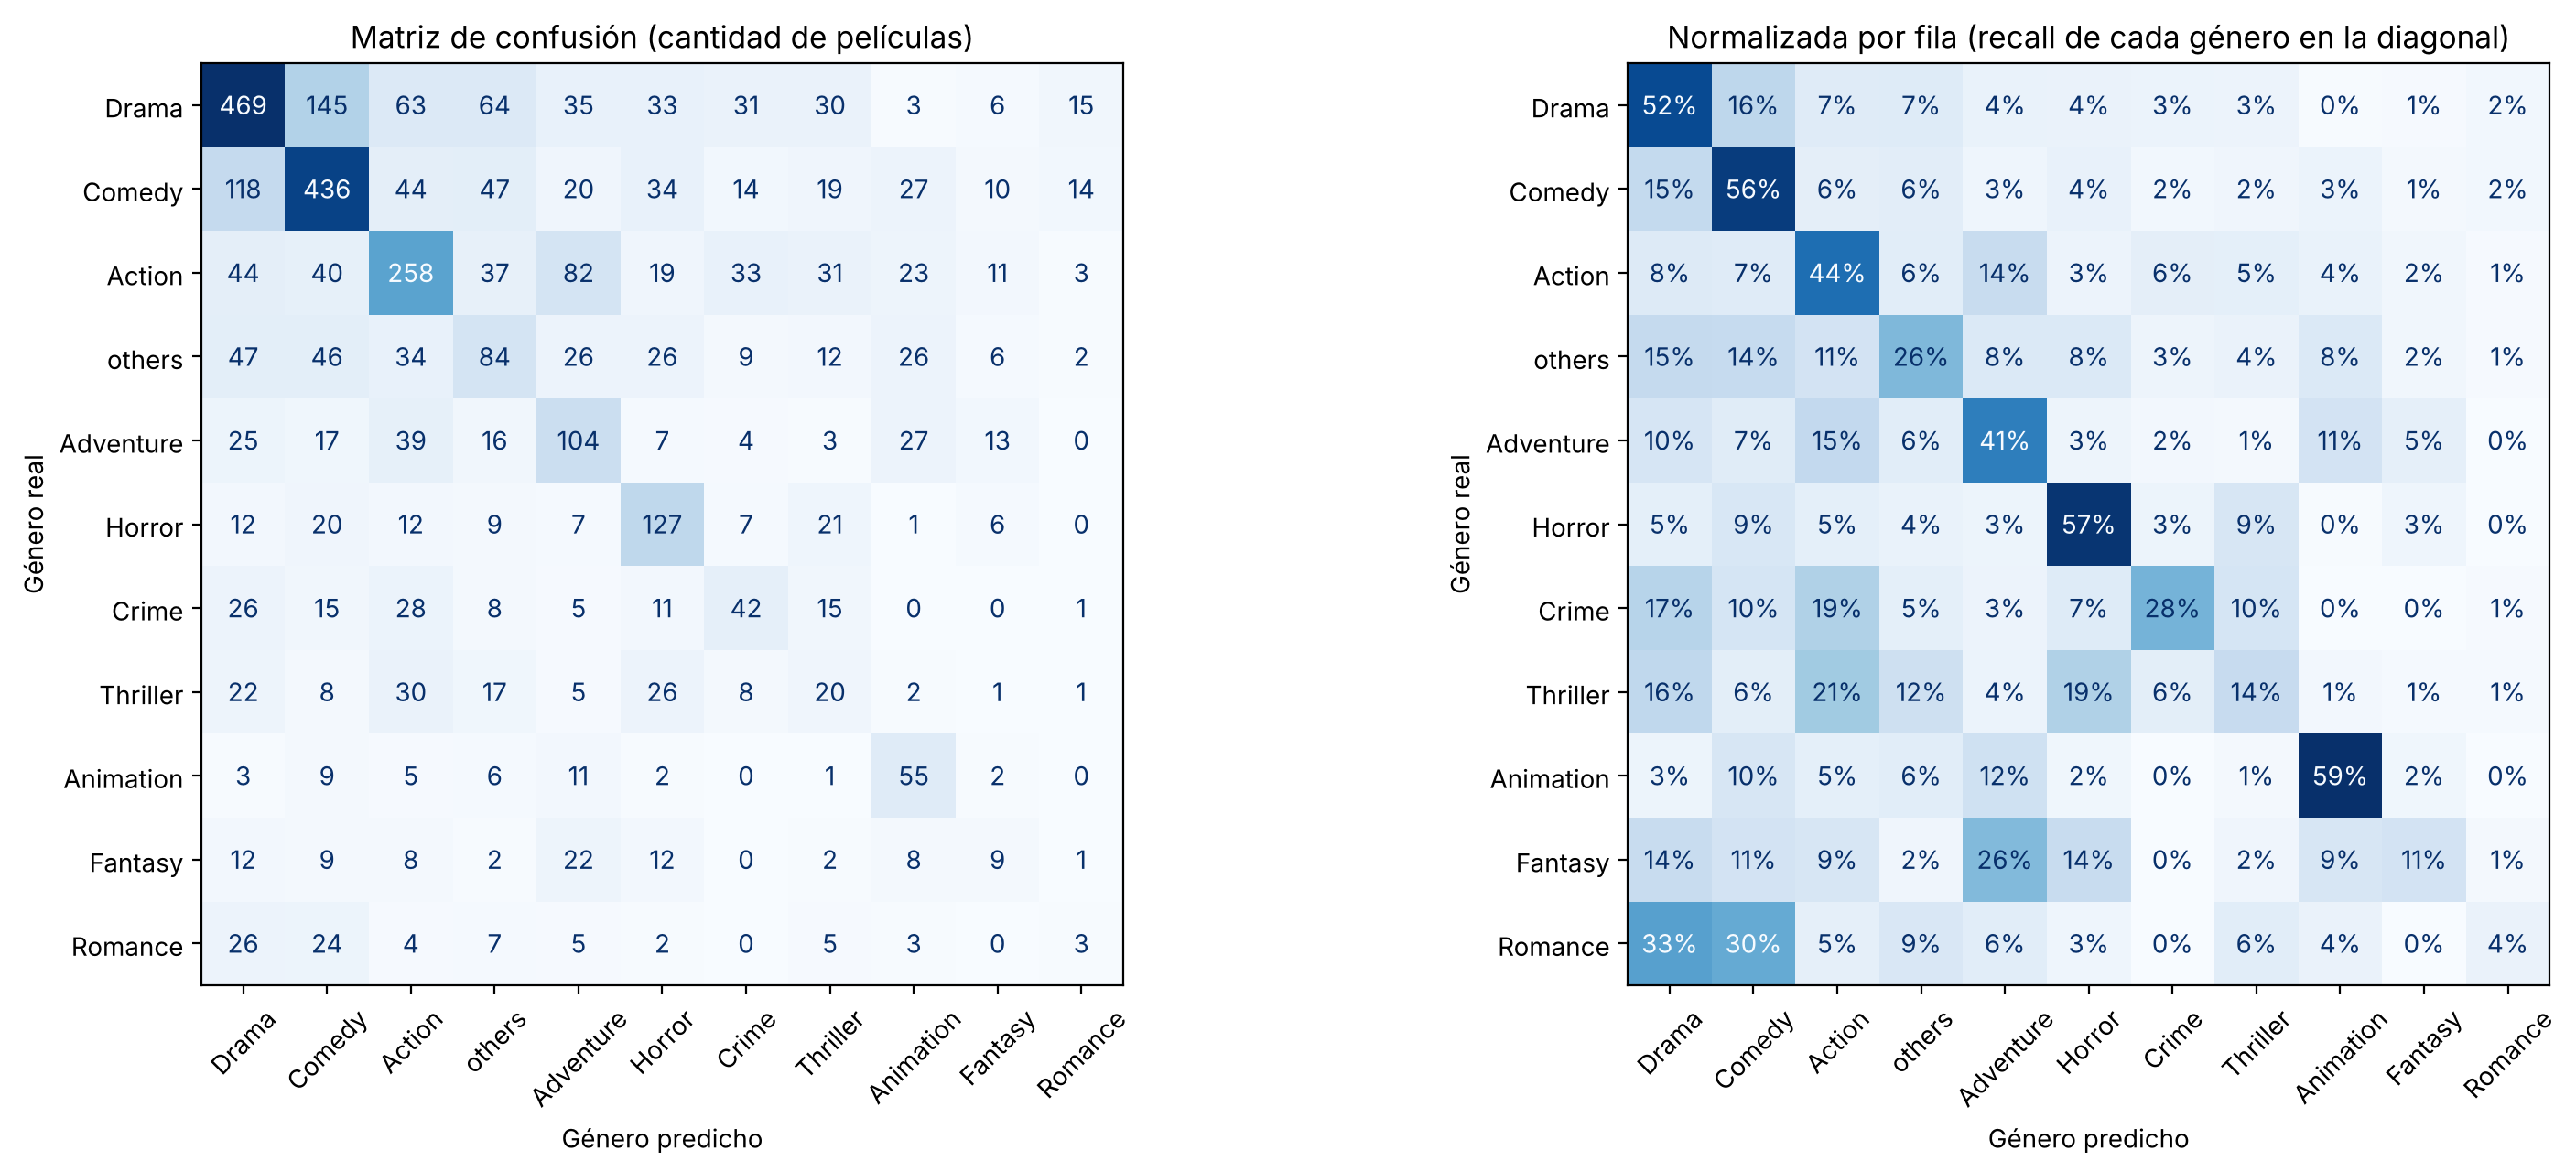

In [13]:
cm = confusion_matrix(y, y_pred, labels=CLASES)
pd.DataFrame(cm, index=CLASES, columns=CLASES).to_csv(f'{CARPETA_RESULTADOS}/nlp_matriz_confusion.csv')
cm_pct = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(
    ax=axes[0], cmap='Blues', values_format='d', colorbar=False, xticks_rotation=45)
axes[0].set_title('Matriz de confusión (cantidad de películas)')
ConfusionMatrixDisplay(cm_pct, display_labels=CLASES).plot(
    ax=axes[1], cmap='Blues', values_format='.0%', colorbar=False, xticks_rotation=45)
axes[1].set_title('Normalizada por fila (recall de cada género en la diagonal)')
for ax in axes:
    ax.set_xlabel('Género predicho')
    ax.set_ylabel('Género real')
plt.tight_layout()
plt.show()

In [14]:
# Confusiones más frecuentes (fuera de la diagonal)
confusiones = pd.DataFrame([
    {'real': CLASES[i], 'predicho': CLASES[j], 'películas': int(cm[i, j]),
     '% del género real': round(100 * cm_pct[i, j], 1)}
    for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j
]).sort_values('películas', ascending=False).head(12).reset_index(drop=True)
confusiones

,real,predicho,películas,% del género real
0,Drama,Comedy,145,16.2
1,Comedy,Drama,118,15.1
2,Action,Adventure,82,14.1
3,Drama,others,64,7.2
4,Drama,Action,63,7.0
5,Comedy,others,47,6.0
6,others,Drama,47,14.8
7,others,Comedy,46,14.5
8,Action,Drama,44,7.6
9,Comedy,Action,44,5.6


### 9.2 Términos más influyentes por género

Se entrena el modelo final con todo el train y se listan, para cada género, los términos con mayor coeficiente: son las palabras que más empujan la predicción hacia ese género. Sirve para verificar que el modelo aprende vocabulario con sentido y para entender las confusiones.

In [15]:
pipe_completo = crear_pipeline_texto(LogisticRegression(C=2, class_weight='balanced', max_iter=3000),
                                     extra=EXTRA_FINAL).fit(X, y)
nombres = pipe_completo.named_steps['prep'].get_feature_names_out()
coef = pipe_completo.named_steps['modelo'].coef_
clases_modelo = pipe_completo.named_steps['modelo'].classes_
terminos = pd.DataFrame({
    genero: [n.replace('texto__', '').replace('num__', '[num] ') for n in nombres[np.argsort(coef[k])[::-1][:10]]]
    for k, genero in enumerate(clases_modelo)
}).T
terminos.columns = [f'{i + 1}°' for i in range(10)]
terminos.loc[CLASES]

,1°,2°,3°,4°,5°,6°,7°,8°,9°,10°
Drama,drama,life,loss,biography,dancer,film,wife,woman,dance,story
Comedy,comedy,independent,love,single,guy,wedding,woman,relationship,alcohol,best
Action,cop,assassin,fight,dystopia,gun,martial,police,agent,fighter,kill
others,documentary,filmmaker,madagascar,war,world,earth,show,west,time,penguin
Adventure,adventure,bond,mission,lion,crocodile,swordplay,sword,mom,find,power
Horror,horror,zombie,spirit,killer,vampire,demon,group,nightmare,evil,suicide
Crime,murder,killer,agent,suspense,gangster,casino,homicide,police,brutal,serial
Thriller,russian,move,dark,bodyguard,train,die,terrorist,nightmare,remote,computer
Animation,dream,fantasia,ranger,wonderful,cripple,space,colorful,musical,park,become
Fantasy,witch,vampire,wish,werewolf,fantasy,castle,undead,heal,creature,angel


**Qué géneros se confunden y por qué.**

- **Drama y Comedy** son la confusión más frecuente en cantidad (145 dramas predichos como comedia y 118 comedias como drama, 15–16% de cada una). Las dos describen personas, relaciones y familia con el mismo vocabulario (*life, love, wife, woman, relationship*), y muchas películas son ambas cosas (comedias dramáticas). Además, `main_genre_top10` es el **primer** género de la lista de cada película: una película con géneros *Comedy, Drama, Romance* queda como Comedy y otra casi igual con *Drama, Comedy* queda como Drama. Parte del error es inevitable, porque la etiqueta depende del orden y no del contenido.
- **Action y Adventure** (14–15% en cada sentido) y **Fantasy → Adventure** (26% de Fantasy): comparten misiones, viajes, peleas y criaturas; las películas de fantasía y aventura suelen tener los dos géneros.
- **Romance** se predice como Drama (33%) o Comedy (30%) y solo 4% como Romance. Entre sus términos más influyentes aparece *comedy*: las palabras clave *romantic comedy* aparecen tanto en películas etiquetadas Romance como Comedy. Un romance casi siempre es también una comedia o un drama, y es la clase más chica.
- **Thriller** se reparte entre Action (21%), Horror (19%) y Drama (16%): no tiene vocabulario propio, y sus términos influyentes (*russian, move, dark, bodyguard*) son poco específicos; suspenso, crimen y terror usan las mismas palabras (*killer, nightmare, death*). Lo mismo le pasa a **Crime** con Action (19%) y Drama (17%).
- **`others`** se confunde con todo (15% Drama, 14% Comedy, 11% Action) porque agrupa géneros distintos; por sus términos (*documentary, war, west, earth*) incluye documentales, bélicas, westerns y ciencia ficción.

Los géneros con mejor F1 son los que tienen vocabulario propio y fácil de reconocer: **Comedy** (0,56) y **Drama** (0,55) por tamaño, **Horror** (0,49; *horror, zombie, vampire, demon*) y **Animation** (0,41, recall 0,59): para Animation pesa además la duración, porque las películas animadas son más cortas.

### 9.3 Efecto del desbalance

Se compara el modelo final con el mismo modelo **sin** `class_weight='balanced'` (mismo `C`), género por género. Con pesos iguales, el modelo minimiza el error total, que está dominado por Drama, Comedy y Action.

In [16]:
pipe_sin_pesos = crear_pipeline_texto(LogisticRegression(C=2, max_iter=3000), extra=EXTRA_FINAL)
y_pred_sin = cross_val_predict(pipe_sin_pesos, X, y, cv=crear_cv(), n_jobs=-1)
rep_sin = pd.DataFrame(classification_report(y, y_pred_sin, labels=CLASES, output_dict=True, zero_division=0)).T

desbalance = pd.DataFrame({
    'películas': reporte.loc[CLASES, 'películas'],
    'predichas sin pesos': pd.Series(y_pred_sin).value_counts().reindex(CLASES, fill_value=0).values,
    'predichas balanced': pd.Series(y_pred).value_counts().reindex(CLASES, fill_value=0).values,
    'recall sin pesos': rep_sin.loc[CLASES, 'recall'],
    'recall balanced': reporte.loc[CLASES, 'recall'],
    'F1 sin pesos': rep_sin.loc[CLASES, 'f1-score'],
    'F1 balanced': reporte.loc[CLASES, 'f1'],
})
resumen = pd.DataFrame({
    'sin pesos': [rep_sin.loc['accuracy', 'precision'], rep_sin.loc['macro avg', 'precision'],
                  rep_sin.loc['macro avg', 'recall'], rep_sin.loc['macro avg', 'f1-score']],
    'balanced': [reporte.loc['accuracy', 'precision'], reporte.loc['macro avg', 'precision'],
                 reporte.loc['macro avg', 'recall'], reporte.loc['macro avg', 'f1']],
}, index=['accuracy', 'precision macro', 'recall macro', 'F1 macro'])
desbalance.to_csv(f'{CARPETA_RESULTADOS}/nlp_desbalance.csv')
display(resumen.round(3))
desbalance.round(3)

,sin pesos,balanced
accuracy,0.461,NaN
precision macro,0.383,0.328
recall macro,0.273,0.356
F1 macro,0.273,0.336


,películas,predichas sin pesos,predichas balanced,recall sin pesos,recall balanced,F1 sin pesos,F1 balanced
Drama,894,1285,804,0.676,0.525,0.554,0.552
Comedy,783,1051,769,0.648,0.557,0.553,0.562
Action,581,768,525,0.596,0.444,0.513,0.467
others,318,109,297,0.094,0.264,0.141,0.273
Adventure,255,149,322,0.227,0.408,0.287,0.360
Horror,222,136,299,0.333,0.572,0.413,0.488
Crime,151,17,148,0.046,0.278,0.083,0.281
Thriller,140,6,159,0.007,0.143,0.014,0.134
Animation,94,76,175,0.340,0.585,0.376,0.409
Fantasy,85,5,64,0.035,0.106,0.067,0.121


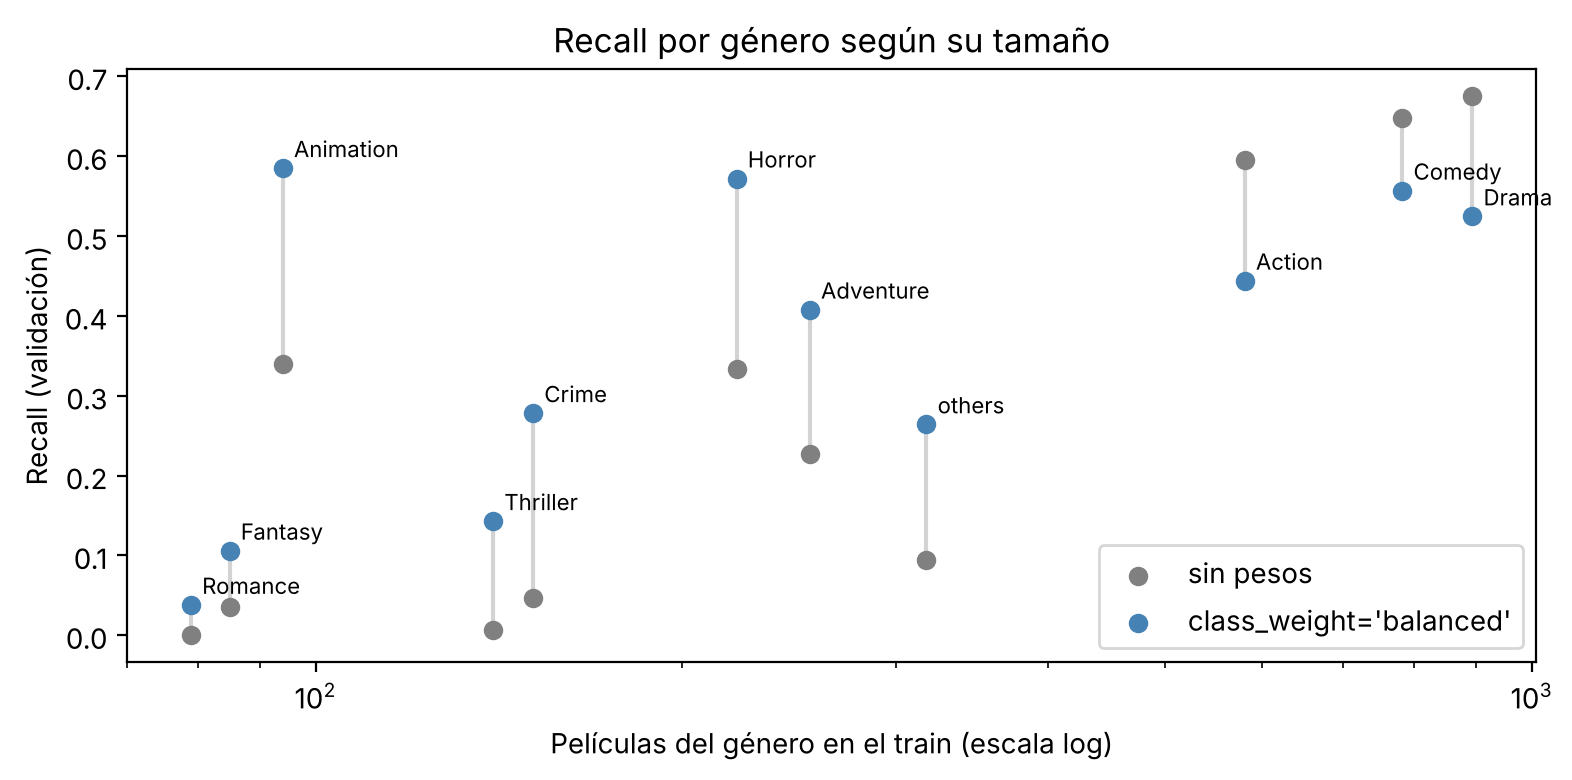

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(desbalance['películas'], desbalance['recall sin pesos'], label='sin pesos', color='gray')
ax.scatter(desbalance['películas'], desbalance['recall balanced'], label="class_weight='balanced'", color='steelblue')
for g in CLASES:
    ax.annotate(g, (desbalance.loc[g, 'películas'], desbalance.loc[g, 'recall balanced']),
                textcoords='offset points', xytext=(4, 4), fontsize=8)
    ax.plot([desbalance.loc[g, 'películas']] * 2,
            [desbalance.loc[g, 'recall sin pesos'], desbalance.loc[g, 'recall balanced']], color='lightgray', zorder=0)
ax.set_xscale('log')
ax.set_xlabel('Películas del género en el train (escala log)')
ax.set_ylabel('Recall (validación)')
ax.set_title('Recall por género según su tamaño')
ax.legend()
plt.tight_layout()
plt.show()

**Efecto del desbalance.** Sin pesos, el modelo predice Drama en 1.285 películas (hay 894) y casi nunca los géneros chicos: Romance **ninguna** vez, Fantasy 5, Thriller 6 y Crime 17. Obtiene el mejor accuracy (0,461) porque acierta mucho Drama, Comedy y Action (recall 0,60–0,68), pero el recall de los géneros chicos es prácticamente 0 y el F1 macro es 0,273. Con `class_weight='balanced'` la cantidad de predicciones de cada género queda cerca de su tamaño real, el recall de los géneros chicos sube mucho (Crime de 0,05 a 0,28, Thriller de 0,01 a 0,14, Animation de 0,34 a 0,59, Horror de 0,33 a 0,57) a costa de bajar el de los grandes, y el F1 macro pasa de 0,273 a 0,336, con apenas 1,5 puntos menos de accuracy.

Aun con pesos, el desempeño sigue ordenado por tamaño: los tres géneros más chicos que no tienen vocabulario propio (Thriller, Fantasy y Romance) quedan con F1 entre 0,05 y 0,13. Los pesos cambian cuánto cuesta cada error, pero no agregan información: con 80 películas de Romance, que además comparten vocabulario con Comedy y Drama, el modelo no tiene con qué separarlas. La excepción es Animation, chica pero con rasgos propios (vocabulario y duración). Las alternativas para atacar el desbalance (sobremuestreo, SMOTE) tampoco generarían información nueva y el problema de fondo es la superposición entre géneros, no solo la cantidad de ejemplos.

In [18]:
# Resumen del modelo final (validación cruzada) para la tabla del informe
fila_final = evaluar_texto(pipe_final, X, y, modelo='Regresión logística + TF-IDF + numéricas',
                           preprocesamiento='lematización (WordNet + POS)', C=2,
                           class_weight='balanced')
pd.DataFrame([fila_final]).to_csv(f'{CARPETA_RESULTADOS}/nlp_final.csv', index=False)
pd.set_option('display.max_colwidth', None)
pd.DataFrame([fila_final]).round(3)

,modelo,preprocesamiento,C,class_weight,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,f1_train
0,Regresión logística + TF-IDF + numéricas,lematización (WordNet + POS),2,balanced,0.446,0.027,0.334,0.038,0.356,0.034,0.336,0.034,0.877


## 10. Conclusiones

- **Resultado:** el modelo final (regresión logística con pesos balanceados sobre TF-IDF del texto lematizado más 6 variables numéricas) obtiene en validación cruzada **accuracy 0,446, precision macro 0,334, recall macro 0,356 y F1 macro 0,336 ± 0,034**, frente a 0,036 de predecir siempre Drama y 0,092 de predecir al azar. Es una tarea difícil: 11 clases desbalanceadas, una de ellas (`others`) heterogénea, y etiquetas que dependen del orden de una lista de géneros superpuestos.
- **Preprocesamiento:** normalizar, tokenizar y quitar stopwords es lo básico; stemming y lematización rinden igual (0,311 y 0,310) y se elige la lematización con etiquetado gramatical por interpretabilidad. El preprocesamiento importa mucho menos que la representación y el tratamiento del desbalance.
- **Representación:** TF-IDF supera claramente a la bolsa de palabras (0,310 contra 0,262); los bigramas no aportan; las palabras clave sí (+0,027) y conviene concatenarlas a la sinopsis en un único texto.
- **Clasificadores:** regresión logística y SVM lineal empatan y superan a Naive Bayes; la decisión que más pesa es `class_weight='balanced'` (+0,05 a +0,06 de F1 macro).
- **Atributos a elección:** las variables numéricas (duración, presupuesto, votos, año) agregan +0,026; idioma y director no aportan.
- **Errores:** las confusiones principales (Drama-Comedy, Action-Adventure, Romance hacia Drama y Comedy, Thriller hacia Action y Horror) se dan entre géneros que comparten vocabulario y que suelen aparecer juntos en una misma película. Una formulación multietiqueta (predecir todos los géneros de cada película) se ajustaría mejor a los datos, pero la consigna pide el género principal.

## 11. Referencias

- Bird, S., Klein, E. y Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly. Documentación de NLTK: https://www.nltk.org
- Manning, C. D., Raghavan, P. y Schütze, H. (2008). *Introduction to Information Retrieval*, cap. 2 (tokenización, stopwords, stemming y lematización), 6 (TF-IDF) y 13 (Naive Bayes). Cambridge University Press.
- Miller, G. A. (1995). WordNet: a lexical database for English. *Communications of the ACM*, 38(11), 39–41.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Porter, M. F. (1980). An algorithm for suffix stripping. *Program*, 14(3), 130–137.
- Rennie, J. D., Shih, L., Teevan, J. y Karger, D. R. (2003). Tackling the poor assumptions of Naive Bayes text classifiers. *ICML 2003*.
- Salton, G. y Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management*, 24(5), 513–523.